# Parts I–II — CIFAR10 experiments

This notebook documents the common CIFAR10 protocol and reads saved evidence. Training is an explicit opt-in. The official training data are split into 45,000 training and 5,000 validation examples, stratified with split seed 42; the official 10,000 test examples are reserved for a separate final evaluation. Both architectures normalize each channel with mean=std=0.5 and use no augmentation.

The MLP uses 3072 → 512 → 256 → 10 with ReLU, default Linear initialization and Adam (lr=0.001, default beta/epsilon values). Four prespecified configurations test dropout (p=0.3), Adam weight decay (1e-4), both, or neither. Adam weight decay here is coupled L2 regularization, **not AdamW**. Weight decay applies to all parameters, including biases. The study uses seed 42, batch size 32, 5,000 updates and evaluation every 500 updates.

The CNN retains the lecture architecture and default initialization, including BatchNorm, with Adam lr=0.001. The same split and preprocessing support a controlled comparison. Whole-split post-update train/validation metrics use evaluation mode; dropout is disabled and BatchNorm buffers remain fixed. The best checkpoint maximizes validation accuracy, with lower validation loss as the tie-breaker. Test results never select hyperparameters.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT=Path.cwd()
if not (ROOT/'cifar_experiments.py').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT.resolve()))
from cifar_experiments import train, test_selected, build_model, make_splits
torch.set_num_threads(1)
RUN_TRAINING=False
RUN_TEST=False
if RUN_TRAINING:
    for variant in ['baseline','dropout','weight_decay','combined']:
        train(architecture='mlp',variant=variant)
# CNN full training requires a separate compute-budget decision.
paths=sorted([*ROOT.glob('Part 1/results/cifar_validation/*/history.json'),
              *ROOT.glob('Part 2/results/cifar_validation/*/history.json')])
runs=[(p.parent,json.loads(p.read_text())) for p in paths]
print('Saved runs:',len(runs))
print('Incomplete runs:',[str(p) for p,r in runs if r['status']!='complete'])
assert runs, 'Run the training command before producing a results notebook.' 

/opt/homebrew/Caskroom/miniconda/base/envs/mldl/lib/python3.11/site-packages/torchvision/io/image.py:14: UserWarning: Failed to load image Python extension: 'dlopen(/opt/homebrew/Caskroom/miniconda/base/envs/mldl/lib/python3.11/site-packages/torchvision/image.so, 0x0006): Library not loaded: @rpath/libjpeg.9.dylib
  Referenced from: <EB3FF92A-5EB1-3EE8-AF8B-5923C1265422> /opt/homebrew/Caskroom/miniconda/base/envs/mldl/lib/python3.11/site-packages/torchvision/image.so
  Reason: tried: '/opt/homebrew/Caskroom/miniconda/base/envs/mldl/lib/python3.11/site-packages/torchvision/../../../libjpeg.9.dylib' (no such file), '/opt/homebrew/Caskroom/miniconda/base/envs/mldl/lib/python3.11/site-packages/torchvision/../../../libjpeg.9.dylib' (no such file), '/opt/homebrew/Caskroom/miniconda/base/envs/mldl/lib/python3.11/lib-dynload/../../libjpeg.9.dylib' (no such file), '/opt/homebrew/Caskroom/miniconda/base/envs/mldl/bin/../lib/libjpeg.9.dylib' (no such file)'If you don't plan on using image functio

Saved runs: 7
Incomplete runs: []


Training: 45000 Validation: 5000 Overlap: 0
Per-class train counts: [4500 4500 4500 4500 4500 4500 4500 4500 4500 4500]
Per-class validation counts: [500 500 500 500 500 500 500 500 500 500]


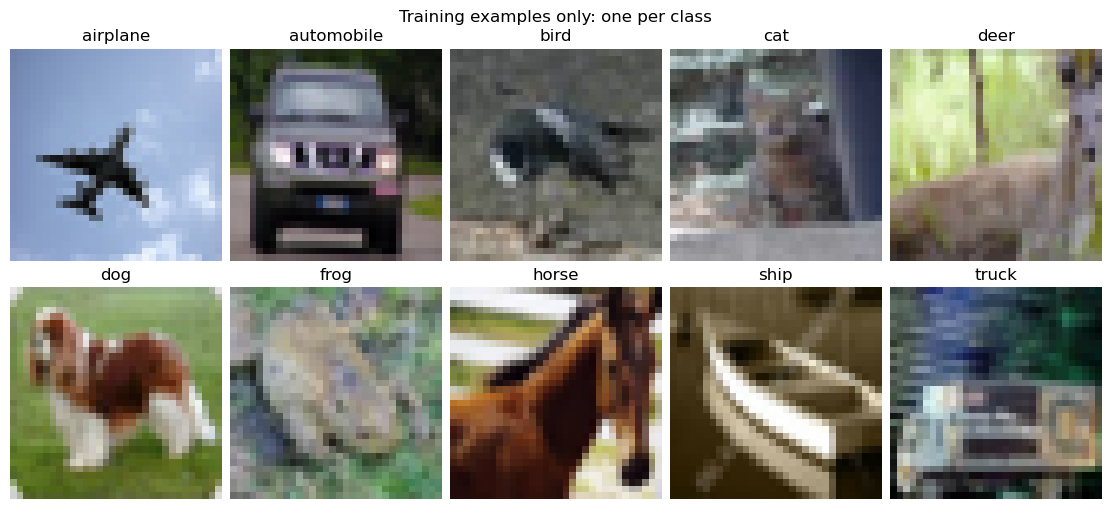

In [2]:
data, train_ids, val_ids=make_splits()
print('Training:',len(train_ids),'Validation:',len(val_ids),'Overlap:',len(np.intersect1d(train_ids,val_ids)))
labels=np.array(data.targets)
print('Per-class train counts:',np.bincount(labels[train_ids]))
print('Per-class validation counts:',np.bincount(labels[val_ids]))
fig,axes=plt.subplots(2,5,figsize=(11,5),constrained_layout=True)
for label,ax in enumerate(axes.flat):
    index=next(int(i) for i in train_ids if labels[i]==label)
    image,_=data[index]
    ax.imshow((image.permute(1,2,0)*0.5+0.5).numpy())
    ax.set_title(data.classes[label]); ax.axis('off')
fig.suptitle('Training examples only: one per class')
plt.show()

In [3]:
rows=['| Architecture | Layer | Parameters | Input → output | Parameter shapes |','|---|---|---:|---|---|']
for architecture in ['mlp','cnn']:
    model=build_model(architecture,'baseline',42,'cpu').eval()
    handles=[]
    def capture(name):
        def hook(module,args,output):
            parameters=list(module.named_parameters(recurse=False))
            rows.append(f'| {architecture} | {name}: {type(module).__name__} | {sum(p.numel() for _,p in parameters)} | {tuple(args[0].shape)} → {tuple(output.shape)} | '+', '.join(f'{n}: {tuple(p.shape)}' for n,p in parameters)+' |')
        return hook
    for name,module in model.named_modules():
        if not list(module.children()): handles.append(module.register_forward_hook(capture(name)))
    with torch.no_grad(): model(torch.zeros(2,3,32,32))
    for handle in handles: handle.remove()
    print(architecture,'trainable parameters:',sum(p.numel() for p in model.parameters()))
display(Markdown('\n'.join(rows)))

mlp trainable parameters: 1707274


cnn trainable parameters: 9231114


| Architecture | Layer | Parameters | Input → output | Parameter shapes |
|---|---|---:|---|---|
| mlp | layers.0: Flatten | 0 | (2, 3, 32, 32) → (2, 3072) |  |
| mlp | layers.1: Linear | 1573376 | (2, 3072) → (2, 512) | weight: (512, 3072), bias: (512,) |
| mlp | layers.2: ReLU | 0 | (2, 512) → (2, 512) |  |
| mlp | layers.3: Dropout | 0 | (2, 512) → (2, 512) |  |
| mlp | layers.4: Linear | 131328 | (2, 512) → (2, 256) | weight: (256, 512), bias: (256,) |
| mlp | layers.5: ReLU | 0 | (2, 256) → (2, 256) |  |
| mlp | layers.6: Dropout | 0 | (2, 256) → (2, 256) |  |
| mlp | layers.7: Linear | 2570 | (2, 256) → (2, 10) | weight: (10, 256), bias: (10,) |
| cnn | features.0: Conv2d | 1792 | (2, 3, 32, 32) → (2, 64, 32, 32) | weight: (64, 3, 3, 3), bias: (64,) |
| cnn | features.1: BatchNorm2d | 128 | (2, 64, 32, 32) → (2, 64, 32, 32) | weight: (64,), bias: (64,) |
| cnn | features.2: ReLU | 0 | (2, 64, 32, 32) → (2, 64, 32, 32) |  |
| cnn | features.3: MaxPool2d | 0 | (2, 64, 32, 32) → (2, 64, 16, 16) |  |
| cnn | features.4: Conv2d | 73856 | (2, 64, 16, 16) → (2, 128, 16, 16) | weight: (128, 64, 3, 3), bias: (128,) |
| cnn | features.5: BatchNorm2d | 256 | (2, 128, 16, 16) → (2, 128, 16, 16) | weight: (128,), bias: (128,) |
| cnn | features.6: ReLU | 0 | (2, 128, 16, 16) → (2, 128, 16, 16) |  |
| cnn | features.7: MaxPool2d | 0 | (2, 128, 16, 16) → (2, 128, 8, 8) |  |
| cnn | features.8: Conv2d | 295168 | (2, 128, 8, 8) → (2, 256, 8, 8) | weight: (256, 128, 3, 3), bias: (256,) |
| cnn | features.9: BatchNorm2d | 512 | (2, 256, 8, 8) → (2, 256, 8, 8) | weight: (256,), bias: (256,) |
| cnn | features.10: ReLU | 0 | (2, 256, 8, 8) → (2, 256, 8, 8) |  |
| cnn | features.11: Conv2d | 590080 | (2, 256, 8, 8) → (2, 256, 8, 8) | weight: (256, 256, 3, 3), bias: (256,) |
| cnn | features.12: BatchNorm2d | 512 | (2, 256, 8, 8) → (2, 256, 8, 8) | weight: (256,), bias: (256,) |
| cnn | features.13: ReLU | 0 | (2, 256, 8, 8) → (2, 256, 8, 8) |  |
| cnn | features.14: MaxPool2d | 0 | (2, 256, 8, 8) → (2, 256, 4, 4) |  |
| cnn | features.15: Conv2d | 1180160 | (2, 256, 4, 4) → (2, 512, 4, 4) | weight: (512, 256, 3, 3), bias: (512,) |
| cnn | features.16: BatchNorm2d | 1024 | (2, 512, 4, 4) → (2, 512, 4, 4) | weight: (512,), bias: (512,) |
| cnn | features.17: ReLU | 0 | (2, 512, 4, 4) → (2, 512, 4, 4) |  |
| cnn | features.18: Conv2d | 2359808 | (2, 512, 4, 4) → (2, 512, 4, 4) | weight: (512, 512, 3, 3), bias: (512,) |
| cnn | features.19: BatchNorm2d | 1024 | (2, 512, 4, 4) → (2, 512, 4, 4) | weight: (512,), bias: (512,) |
| cnn | features.20: ReLU | 0 | (2, 512, 4, 4) → (2, 512, 4, 4) |  |
| cnn | features.21: MaxPool2d | 0 | (2, 512, 4, 4) → (2, 512, 2, 2) |  |
| cnn | features.22: Conv2d | 2359808 | (2, 512, 2, 2) → (2, 512, 2, 2) | weight: (512, 512, 3, 3), bias: (512,) |
| cnn | features.23: BatchNorm2d | 1024 | (2, 512, 2, 2) → (2, 512, 2, 2) | weight: (512,), bias: (512,) |
| cnn | features.24: ReLU | 0 | (2, 512, 2, 2) → (2, 512, 2, 2) |  |
| cnn | features.25: Conv2d | 2359808 | (2, 512, 2, 2) → (2, 512, 2, 2) | weight: (512, 512, 3, 3), bias: (512,) |
| cnn | features.26: BatchNorm2d | 1024 | (2, 512, 2, 2) → (2, 512, 2, 2) | weight: (512,), bias: (512,) |
| cnn | features.27: ReLU | 0 | (2, 512, 2, 2) → (2, 512, 2, 2) |  |
| cnn | features.28: MaxPool2d | 0 | (2, 512, 2, 2) → (2, 512, 1, 1) |  |
| cnn | classifier: Linear | 5130 | (2, 512) → (2, 10) | weight: (10, 512), bias: (10,) |

## Forward, backward and update dimensions

For the MLP, an image batch `(B,3,32,32)` is flattened to `(B,3072)`. With PyTorch's weight storage, each affine layer computes `X @ W.T + b`. Backpropagation has `dW = dZ.T @ X`, `db = dZ.sum(0)`, and `dX = dZ @ W`. ReLU and dropout preserve activation dimensions. Cross-entropy maps logits `(B,10)` and integer labels `(B,)` to a scalar. Adam maintains first- and second-moment tensors of the same shape as each parameter.

For the CNN, each 3×3 stride-1 padded convolution preserves spatial size, and each 3×3 stride-2 padded max pool reduces it: 32 → 16 → 8 → 4 → 2 → 1. The final `(B,512,1,1)` map is flattened to `(B,512)` before the classifier. A convolution weight is `(C_out,C_in,3,3)`; its gradient has the same shape. BatchNorm's gamma and beta are trainable, while running mean/variance and the batch counter are buffers, excluded from the trainable parameter count. These buffers update only on training examples.

With 45,000 training examples and batch size 32, the last batch in each epoch has 8 examples. It is retained. The saved `samples_seen` and `epoch_equivalent` fields account for these partial batches exactly.

| Model / variant | Budget | Seed | Device | Status | Last train | Last val | Best val | Selected update | Seconds |
|---|---:|---:|---|---|---:|---:|---:|---:|---:|
| mlp / baseline | 5000 | 42 | cpu | complete | 55.97% | 47.68% | 50.56% | 4500 | 46.9 |
| mlp / baseline | 20000 | 42 | cuda | complete | 80.19% | 52.62% | 52.62% | 20000 | 196.1 |
| mlp / combined | 5000 | 42 | cpu | complete | 48.29% | 44.40% | 45.72% | 3500 | 53.7 |
| mlp / dropout | 5000 | 42 | cpu | complete | 49.52% | 45.60% | 47.02% | 4500 | 48.9 |
| mlp / weight_decay | 5000 | 42 | cpu | complete | 53.17% | 47.16% | 49.38% | 4500 | 50.6 |
| cnn / baseline | 20000 | 42 | cuda | complete | 96.42% | 82.64% | 83.68% | 16000 | 366.6 |
| cnn / baseline | 5000 | 42 | cuda | complete | 83.92% | 79.64% | 79.64% | 5000 | 165.2 |

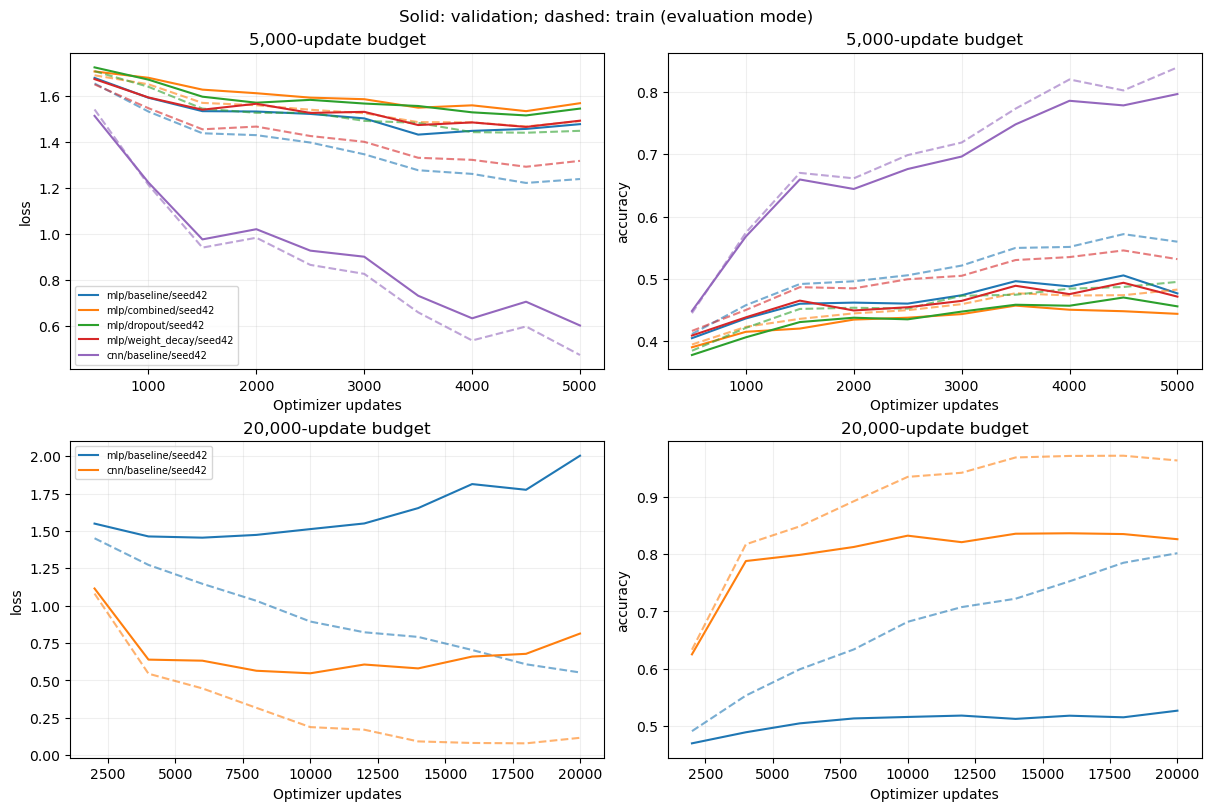

In [4]:
table=['| Model / variant | Budget | Seed | Device | Status | Last train | Last val | Best val | Selected update | Seconds |','|---|---:|---:|---|---|---:|---:|---:|---:|---:|']
for path,run in runs:
    c=run['config']; last=run['history'][-1]
    best=next(r for r in run['history'] if r['step']==run['best_step'])
    table.append(f"| {c['architecture']} / {c['variant']} | {c['steps']} | {c['seed']} | {c['device']} | {run['status']} | {last['train_accuracy']:.2%} | {last['val_accuracy']:.2%} | {best['val_accuracy']:.2%} | {run['best_step']} | {last['elapsed_seconds']:.1f} |")
display(Markdown('\n'.join(table)))
budgets=sorted({r['config']['steps'] for _,r in runs})
fig,axes=plt.subplots(len(budgets),2,figsize=(12,4*len(budgets)),squeeze=False,constrained_layout=True)
for row,budget in enumerate(budgets):
    for path,run in runs:
        c=run['config']
        if c['steps']!=budget: continue
        h=run['history'];label=f"{c['architecture']}/{c['variant']}/seed{c['seed']}"
        for ax,metric in zip(axes[row],['loss','accuracy']):
            line=ax.plot([r['step'] for r in h],[r['val_'+metric] for r in h],label=label)[0]
            ax.plot([r['step'] for r in h],[r['train_'+metric] for r in h],'--',color=line.get_color(),alpha=0.6)
            ax.set(xlabel='Optimizer updates',ylabel=metric,title=f'{budget:,}-update budget');ax.grid(alpha=0.2)
    axes[row,0].legend(fontsize=7)
fig.suptitle('Solid: validation; dashed: train (evaluation mode)')
(ROOT/'results').mkdir(exist_ok=True)
fig.savefig(ROOT/'results/cifar_learning_curves.png',dpi=160)
plt.show()


**Frozen validation selection:** Part 1/results/cifar_validation/baseline-seed42-avwupsc2

Held-out test accuracy: 0.5017
Held-out test cross-entropy: 1.46298515625


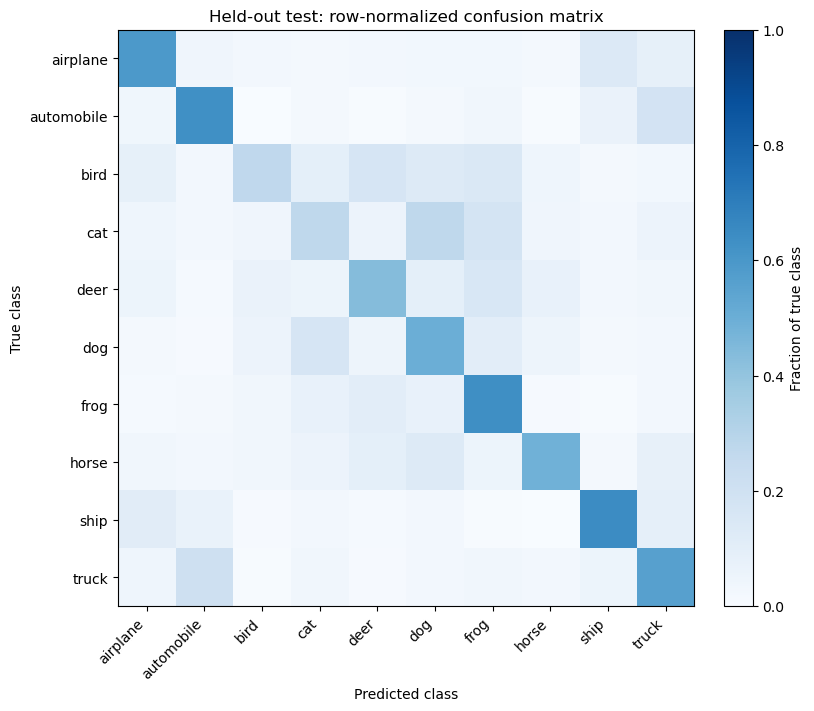

airplane: recall=59.00%
automobile: recall=63.00%
bird: recall=26.60%
cat: recall=27.00%
deer: recall=43.50%
dog: recall=49.80%
frog: recall=63.50%
horse: recall=48.50%
ship: recall=64.60%
truck: recall=56.20%


In [5]:
# Pin a frozen decision in selection.json before consulting the test set.
selection_file=ROOT/'results/cifar_mlp_selection.json'
if selection_file.exists():
    selection=json.loads(selection_file.read_text())
    SELECTED=ROOT/selection['selected_run']
    display(Markdown('**Frozen validation selection:** '+str(SELECTED.relative_to(ROOT))))
    if RUN_TEST: test_selected(SELECTED)
else:
    SELECTED=None
    print('No frozen selection yet. No test data will be evaluated.')
if SELECTED is not None and (SELECTED/'test_metrics.json').exists():
    metrics=json.loads((SELECTED/'test_metrics.json').read_text())
    print('Held-out test accuracy:',metrics['test_accuracy'])
    print('Held-out test cross-entropy:',metrics['test_loss'])
    confusion=np.array(metrics['confusion_matrix'])
    fig,ax=plt.subplots(figsize=(8,7),constrained_layout=True)
    im=ax.imshow(confusion/confusion.sum(1,keepdims=True),vmin=0,vmax=1,cmap='Blues')
    ax.set(xticks=range(10),yticks=range(10),xticklabels=metrics['classes'],yticklabels=metrics['classes'],xlabel='Predicted class',ylabel='True class',title='Held-out test: row-normalized confusion matrix')
    plt.setp(ax.get_xticklabels(),rotation=45,ha='right')
    fig.colorbar(im,ax=ax,label='Fraction of true class')
    fig.savefig(SELECTED/'confusion_matrix.png',dpi=160)
    plt.show()
    for label,accuracy in zip(metrics['classes'],confusion.diagonal()/confusion.sum(1)):
        print(f'{label}: recall={accuracy:.2%}')
else:
    print('Final test evaluation is pending.')

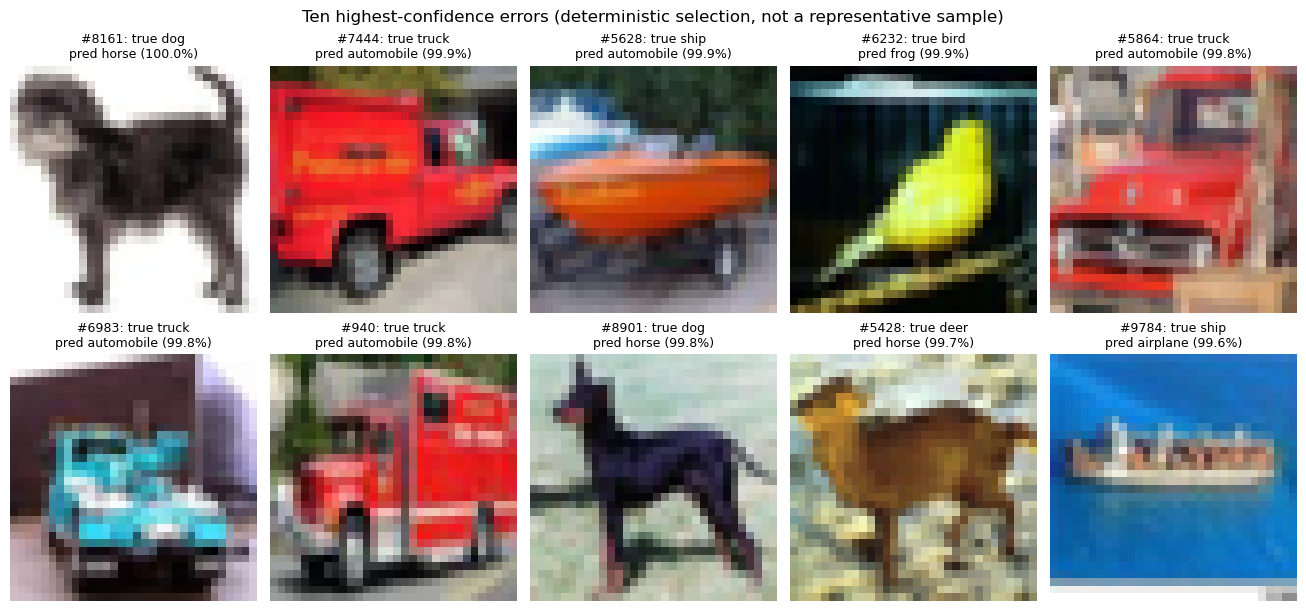

In [6]:
if SELECTED is not None and (SELECTED/'test_predictions.npz').exists():
    from torchvision.datasets import CIFAR10
    predictions=np.load(SELECTED/'test_predictions.npz')
    wrong=np.flatnonzero(predictions['predictions']!=predictions['targets'])
    confidence=predictions['probabilities'].max(1)
    ordered=wrong[np.argsort(-confidence[wrong],kind='stable')][:10]
    raw_test=CIFAR10(ROOT/'data',train=False,download=False)
    fig,axes=plt.subplots(2,5,figsize=(13,6),constrained_layout=True)
    for ax,index in zip(axes.flat,ordered):
        image,target=raw_test[int(index)]
        predicted=int(predictions['predictions'][index])
        ax.imshow(image); ax.axis('off')
        ax.set_title(f'#{index}: true {raw_test.classes[target]}\npred {raw_test.classes[predicted]} ({confidence[index]:.1%})',fontsize=9)
    for ax in list(axes.flat)[len(ordered):]: ax.axis('off')
    fig.suptitle('Ten highest-confidence errors (deterministic selection, not a representative sample)')
    fig.savefig(SELECTED/'high_confidence_errors.png',dpi=160)
    plt.show()

## Interpretation and limits

Compare each regularization variant with the baseline at the same update budget and initialization. A larger train–validation gap may indicate overfitting, but a single seed is insufficient to establish a reliable advantage. Dropout can also slow fitting, especially within a short budget; a lower score does not prove that dropout never helps. Validation selection is optimistic on that validation set, which is why the final test evaluation is kept separate.

The MLP discards spatial structure when flattening pixels. The CNN encodes locality and shared filters, but also has substantially more parameters. A comparison therefore evaluates these concrete architectures and budgets, not an isolated causal effect of convolution. The initial MLP and CNN runs use different hardware/software environments; the extended pair shares one A800 environment. Compare like budgets and identify the execution environment before interpreting speed or convergence differences.

High-confidence errors are selected by an explicit rule and illustrate failure cases; they do not estimate the frequency of those failures. Confusion matrices and per-class recalls use all test examples. Saved checkpoints support inspection and final evaluation; the CIFAR runner does not promise exact interrupted-training continuation.

## Prespecified 20,000-update follow-up

The longer-budget comparison trains fresh MLP and CNN baselines with seed 42, batch size 32, evaluation every 2,000 updates, and the same saved split. Both run on the same A800 environment. The baseline MLP variant was chosen by the initial validation study; no architecture or hyperparameter was selected using the extended test results. The protocol is preserved in `results/cifar_extended_study.json`.

These runs are not exact resumptions. The initial CNN used PyTorch 2.10, while the extended pair used PyTorch 2.8; the local MLP study used PyTorch 2.5. Thus between-stage differences are not a strictly isolated intervention on training duration. Within the extended pair, data, update budget, software and hardware are matched.

In [7]:
extended_path=ROOT/'results/cifar_extended_study.json'
if extended_path.exists():
    extended=json.loads(extended_path.read_text())
    assert extended['status']=='complete'
    rows=['| Model | Budget | Selected update | Validation accuracy | Test accuracy | Test CE |','|---|---:|---:|---:|---:|---:|']
    for record in extended['records']:
        directory=ROOT/record['run'];run=json.loads((directory/'history.json').read_text())
        best=next(row for row in run['history'] if row['step']==run['best_step'])
        metric=json.loads((directory/'test_metrics.json').read_text())
        rows.append(f"| {record['architecture']} | {run['config']['steps']} | {run['best_step']} | {best['val_accuracy']:.2%} | {metric['test_accuracy']:.2%} | {metric['test_loss']:.4f} |")
    display(Markdown('\n'.join(rows)))
else:
    extended=None
    print('Extended results have not been synchronized yet.')

| Model | Budget | Selected update | Validation accuracy | Test accuracy | Test CE |
|---|---:|---:|---:|---:|---:|
| mlp | 20000 | 20000 | 52.62% | 52.30% | 1.9808 |
| cnn | 20000 | 16000 | 83.68% | 82.83% | 0.6970 |

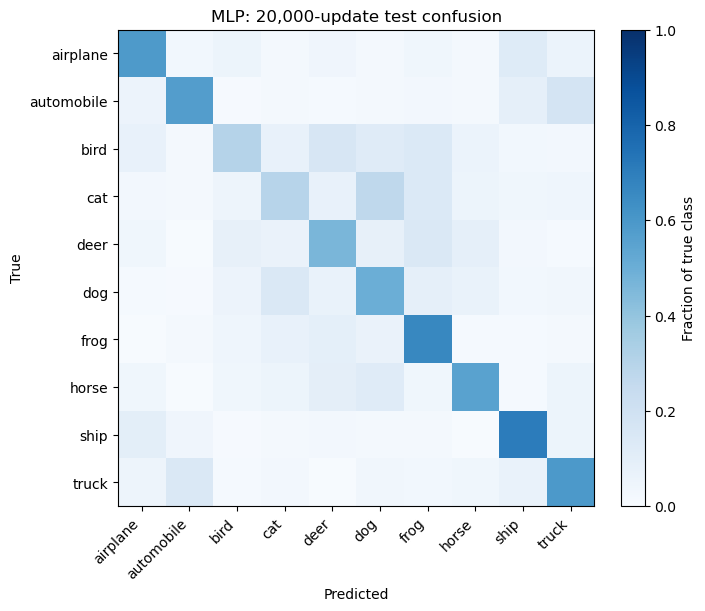

airplane: 58.80%
automobile: 57.30%
bird: 30.40%
cat: 29.60%
deer: 46.20%
dog: 49.70%
frog: 66.20%
horse: 55.10%
ship: 70.60%
truck: 59.10%


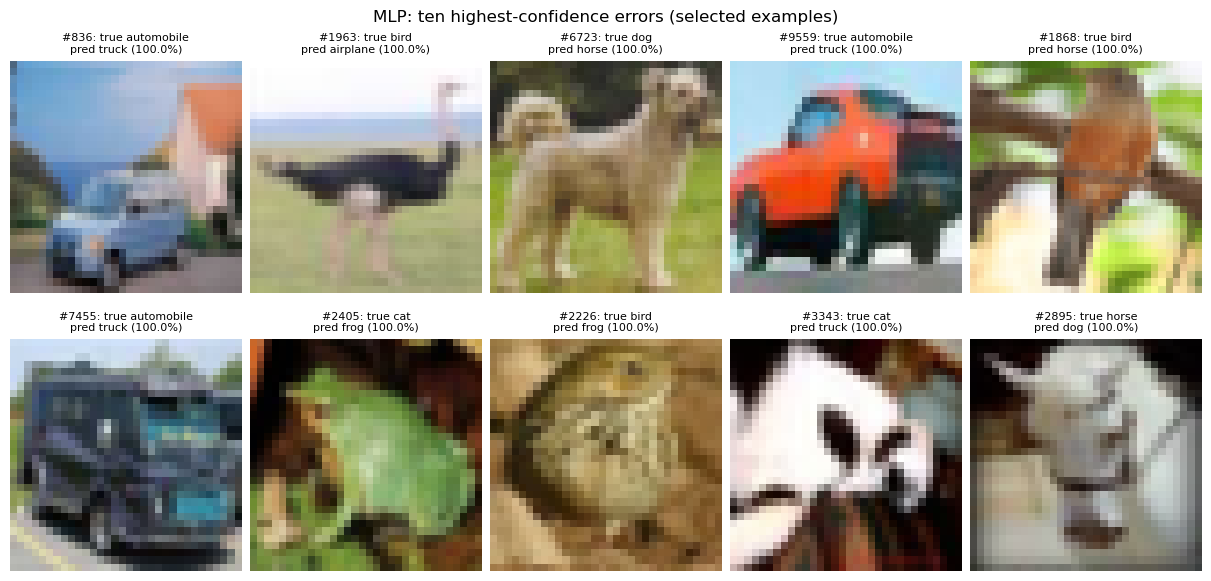

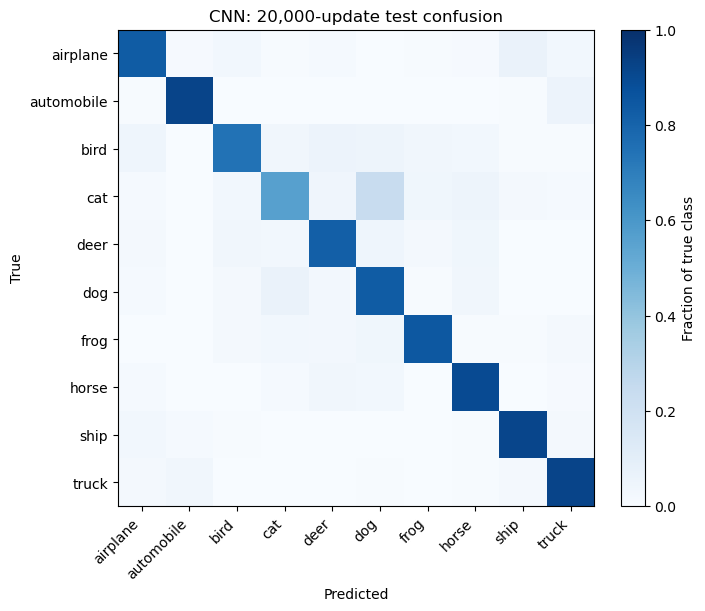

airplane: 83.00%
automobile: 92.10%
bird: 74.30%
cat: 56.10%
deer: 82.00%
dog: 83.10%
frog: 84.70%
horse: 89.60%
ship: 91.50%
truck: 91.90%


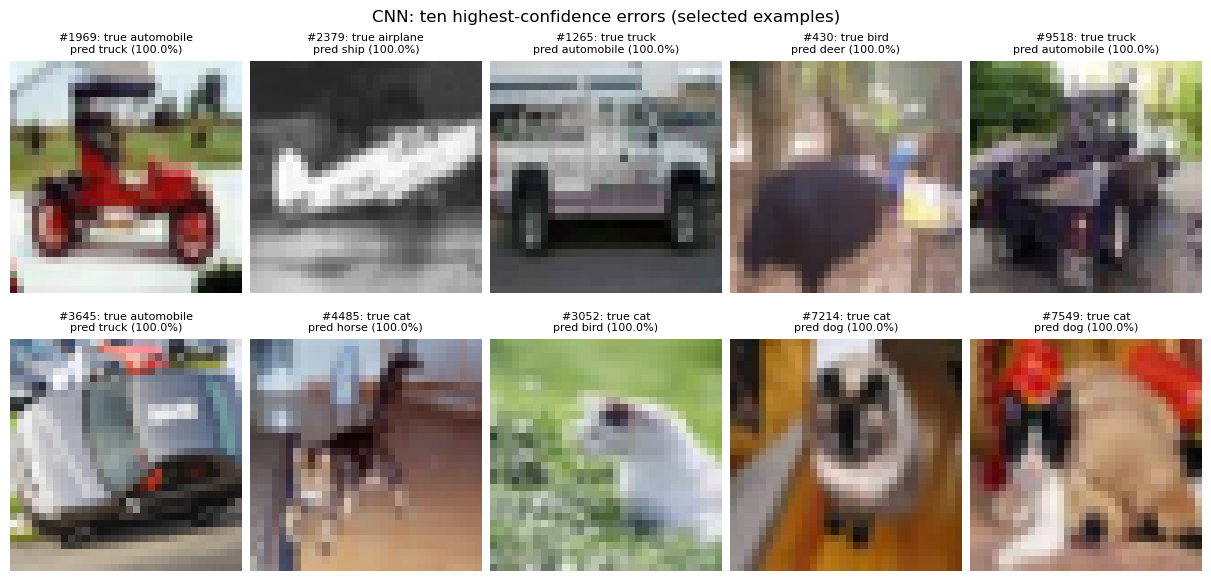

In [8]:
if extended is not None:
    from torchvision.datasets import CIFAR10
    raw_test=CIFAR10(ROOT/'data',train=False,download=False)
    for record in extended['records']:
        directory=ROOT/record['run'];metric=json.loads((directory/'test_metrics.json').read_text())
        cm=np.array(metric['confusion_matrix'])
        fig,ax=plt.subplots(figsize=(7,6),constrained_layout=True)
        im=ax.imshow(cm/cm.sum(1,keepdims=True),vmin=0,vmax=1,cmap='Blues')
        ax.set(xticks=range(10),yticks=range(10),xticklabels=metric['classes'],yticklabels=metric['classes'],xlabel='Predicted',ylabel='True',title=f"{record['architecture'].upper()}: 20,000-update test confusion")
        plt.setp(ax.get_xticklabels(),rotation=45,ha='right');fig.colorbar(im,ax=ax,label='Fraction of true class')
        fig.savefig(directory/'confusion_matrix.png',dpi=160);plt.show()
        for label,recall in zip(metric['classes'],cm.diagonal()/cm.sum(1)): print(f'{label}: {recall:.2%}')
        saved=np.load(directory/'test_predictions.npz');wrong=np.flatnonzero(saved['targets']!=saved['predictions'])
        confidence=saved['probabilities'].max(1);ordered=wrong[np.argsort(-confidence[wrong],kind='stable')][:10]
        fig,axes=plt.subplots(2,5,figsize=(12,5.8),constrained_layout=True)
        for ax,index in zip(axes.flat,ordered):
            image,target=raw_test[int(index)];predicted=int(saved['predictions'][index]);ax.imshow(image);ax.axis('off')
            ax.set_title(f'#{index}: true {raw_test.classes[target]}\npred {raw_test.classes[predicted]} ({confidence[index]:.1%})',fontsize=8)
        for ax in list(axes.flat)[len(ordered):]:ax.axis('off')
        fig.suptitle(record['architecture'].upper()+': ten highest-confidence errors (selected examples)')
        fig.savefig(directory/'high_confidence_errors.png',dpi=160);plt.show()